<a href="https://colab.research.google.com/github/PavelShershov/Machine_Learning/blob/main/AcFun_Shershov.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Выполнить классификацию изображений MNIST, Fashion-MNIST и CIFAR-10. Подготовить и нормализовать данные, построить и обучить модель Keras с использованием скрытых и выходного слоёв, оценить качество классификации.

In [ ]:
import gc
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

np.random.seed(42)
tf.keras.utils.set_random_seed(42)

for gpu in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass

print("TensorFlow:", tf.__version__)
print("Устройства GPU:", tf.config.list_physical_devices("GPU"))
if not tf.config.list_physical_devices("GPU"):
    print("Внимание: GPU не обнаружен. Обучение будет выполняться на CPU.")

TensorFlow: 2.22.0-rc1
Устройства GPU: []
Внимание: GPU не обнаружен. Обучение будет выполняться на CPU.


In [ ]:
def load_dataset(name):
    if name == "MNIST":
        (x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
    elif name == "Fashion-MNIST":
        (x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()
    elif name == "CIFAR-10":
        (x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()
    else:
        raise ValueError(f"Неизвестный набор данных: {name}")

    x_train = x_train.reshape(len(x_train), -1).astype(np.float32) / 255.0
    x_test = x_test.reshape(len(x_test), -1).astype(np.float32) / 255.0
    y_train = np.asarray(y_train).reshape(-1).astype(np.int64)
    y_test = np.asarray(y_test).reshape(-1).astype(np.int64)

    print(f"{name}:")
    print("  Обучающая выборка:", x_train.shape, y_train.shape)
    print("  Тестовая выборка: ", x_test.shape, y_test.shape)
    print("  Диапазон признаков:", float(x_train.min()), "—", float(x_train.max()))

    return {
        "x_train": x_train,
        "y_train": y_train,
        "x_test": x_test,
        "y_test": y_test
    }


datasets = {}
for dataset_name in ("MNIST", "Fashion-MNIST", "CIFAR-10"):
    datasets[dataset_name] = load_dataset(dataset_name)

MNIST:
  Обучающая выборка: (60000, 784) (60000,)
  Тестовая выборка:  (10000, 784) (10000,)
  Диапазон признаков: 0.0 — 1.0
Fashion-MNIST:
  Обучающая выборка: (60000, 784) (60000,)
  Тестовая выборка:  (10000, 784) (10000,)
  Диапазон признаков: 0.0 — 1.0
CIFAR-10:
  Обучающая выборка: (50000, 3072) (50000,)
  Тестовая выборка:  (10000, 3072) (10000,)
  Диапазон признаков: 0.0 — 1.0


In [ ]:
def build_model(input_size, hidden_units=(128,), activation="relu"):
    inputs = keras.Input(shape=(input_size,), name="input_layer")
    x = inputs

    for layer_number, units in enumerate(hidden_units, start=1):
        x = keras.layers.Dense(
            units,
            activation=activation,
            name=f"hidden_layer_{layer_number}"
        )(x)

    outputs = keras.layers.Dense(
        10,
        activation="softmax",
        name="output_layer"
    )(x)

    model = keras.Model(inputs=inputs, outputs=outputs)

    model.compile(
        optimizer=keras.optimizers.Adam(),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


results = []


def plot_history(history, title):
    history_data = history.history
    epochs_range = range(1, len(history_data["loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(epochs_range, history_data["accuracy"], marker="o", label="Accuracy")
    axes[0].plot(epochs_range, history_data["val_accuracy"], marker="o", label="Validation Accuracy")
    axes[0].set_title("Точность")
    axes[0].set_xlabel("Эпоха")
    axes[0].set_ylabel("Accuracy")
    axes[0].grid(True)
    axes[0].legend()

    axes[1].plot(epochs_range, history_data["loss"], marker="o", label="Loss")
    axes[1].plot(epochs_range, history_data["val_loss"], marker="o", label="Validation Loss")
    axes[1].set_title("Функция потерь")
    axes[1].set_xlabel("Эпоха")
    axes[1].set_ylabel("Loss")
    axes[1].grid(True)
    axes[1].legend()

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def run_experiment(
    dataset_name,
    experiment_name,
    hidden_units=(128,),
    activation="relu",
    epochs=5,
    batch_size=32
):
    data = datasets[dataset_name]
    keras.backend.clear_session()
    gc.collect()
    tf.keras.utils.set_random_seed(42)

    model = build_model(
        input_size=data["x_train"].shape[1],
        hidden_units=hidden_units,
        activation=activation
    )

    print(f"\n{dataset_name} — {experiment_name}")
    print("Скрытые слои:", hidden_units)
    print("Функция активации:", activation)
    print("Эпохи:", epochs, "| Batch size:", batch_size)
    model.summary()

    start_time = time.perf_counter()

    history = model.fit(
        data["x_train"],
        data["y_train"],
        epochs=epochs,
        batch_size=batch_size,
        validation_split=0.1,
        shuffle=True,
        verbose=2
    )

    training_time = time.perf_counter() - start_time
    test_loss, test_accuracy = model.evaluate(
        data["x_test"],
        data["y_test"],
        verbose=0
    )

    train_accuracy = history.history["accuracy"][-1]
    validation_accuracy = history.history["val_accuracy"][-1]

    result = {
        "Датасет": dataset_name,
        "Эксперимент": experiment_name,
        "Скрытые слои": str(hidden_units),
        "Активация": activation,
        "Эпохи": epochs,
        "Batch size": batch_size,
        "Accuracy (train)": train_accuracy,
        "Accuracy (validation)": validation_accuracy,
        "Accuracy (test)": test_accuracy,
        "Loss (test)": test_loss,
        "Время обучения, сек.": training_time
    }
    results.append(result)

    print(f"\nВремя обучения: {training_time:.2f} сек.")
    print(f"Accuracy на обучении:   {train_accuracy * 100:.2f}%")
    print(f"Accuracy на validation: {validation_accuracy * 100:.2f}%")
    print(f"Accuracy на тесте:      {test_accuracy * 100:.2f}%")
    print(f"Loss на тесте:          {test_loss:.4f}")

    plot_history(history, f"{dataset_name}: {experiment_name}")

    del model
    gc.collect()

    return history



MNIST — Базовая модель по лекции
Скрытые слои: (128,)
Функция активации: relu
Эпохи: 5 | Batch size: 32


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ hidden_layer_1 (Dense)               │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ output_layer (Dense)                 │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
1688/1688 - 2s - 1ms/step - accuracy: 0.9234 - loss: 0.2682 - val_accuracy: 0.9667 - val_loss: 0.1211
Epoch 2/5
1688/1688 - 2s - 1ms/step - accuracy: 0.9655 - loss: 0.1175 - val_accuracy: 0.9733 - val_loss: 0.0954
Epoch 3/5
1688/1688 - 2s - 1ms/step - accuracy: 0.9766 - loss: 0.0808 - val_accuracy: 0.9745 - val_loss: 0.0902
Epoch 4/5
1688/1688 - 2s - 1ms/step - accuracy: 0.9830 - loss: 0.0597 - val_accuracy: 0.9745 - val_loss: 0.0893
Epoch 5/5
1688/1688 - 2s - 1ms/step - accuracy: 0.9874 - loss: 0.0448 - val_accuracy: 0.9752 - val_loss: 0.0891

Время обучения: 9.55 сек.
Accuracy на обучении:   98.74%
Accuracy на validation: 97.52%
Accuracy на тесте:      97.32%
Loss на тесте:          0.0898


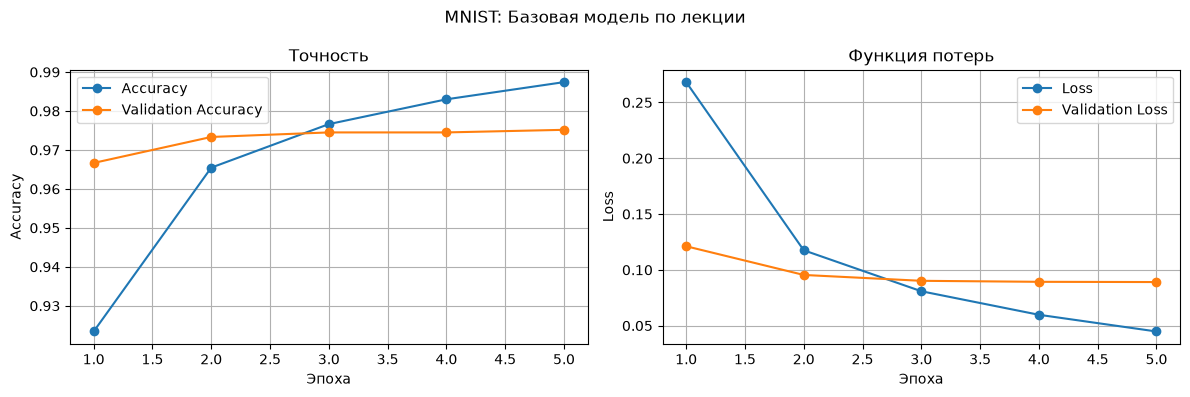


Fashion-MNIST — Базовая модель по лекции
Скрытые слои: (128,)
Функция активации: relu
Эпохи: 5 | Batch size: 32


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ hidden_layer_1 (Dense)               │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ output_layer (Dense)                 │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
1688/1688 - 2s - 1ms/step - accuracy: 0.8199 - loss: 0.5056 - val_accuracy: 0.8602 - val_loss: 0.3985
Epoch 2/5
1688/1688 - 2s - 1ms/step - accuracy: 0.8630 - loss: 0.3776 - val_accuracy: 0.8707 - val_loss: 0.3654
Epoch 3/5
1688/1688 - 2s - 1ms/step - accuracy: 0.8772 - loss: 0.3390 - val_accuracy: 0.8730 - val_loss: 0.3503
Epoch 4/5
1688/1688 - 2s - 1ms/step - accuracy: 0.8856 - loss: 0.3132 - val_accuracy: 0.8755 - val_loss: 0.3451
Epoch 5/5
1688/1688 - 2s - 1ms/step - accuracy: 0.8934 - loss: 0.2935 - val_accuracy: 0.8805 - val_loss: 0.3338

Время обучения: 9.22 сек.
Accuracy на обучении:   89.34%
Accuracy на validation: 88.05%
Accuracy на тесте:      87.23%
Loss на тесте:          0.3577


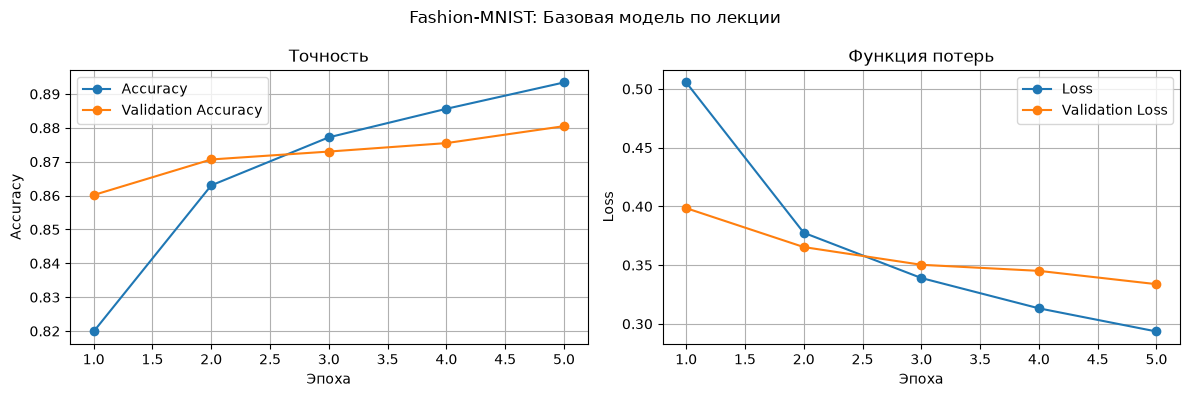


CIFAR-10 — Базовая модель по лекции
Скрытые слои: (128,)
Функция активации: relu
Эпохи: 5 | Batch size: 32


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 3072)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ hidden_layer_1 (Dense)               │ (None, 128)                 │         393,344 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ output_layer (Dense)                 │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 394,634 (1.51 MB)

 Trainable params: 394,634 (1.51 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
1407/1407 - 2s - 2ms/step - accuracy: 0.3127 - loss: 1.9220 - val_accuracy: 0.3200 - val_loss: 1.9013
Epoch 2/5
1407/1407 - 2s - 1ms/step - accuracy: 0.3710 - loss: 1.7652 - val_accuracy: 0.3612 - val_loss: 1.8139
Epoch 3/5
1407/1407 - 2s - 1ms/step - accuracy: 0.3908 - loss: 1.7125 - val_accuracy: 0.3792 - val_loss: 1.7868
Epoch 4/5
1407/1407 - 2s - 1ms/step - accuracy: 0.4038 - loss: 1.6815 - val_accuracy: 0.3964 - val_loss: 1.7419
Epoch 5/5
1407/1407 - 2s - 1ms/step - accuracy: 0.4113 - loss: 1.6606 - val_accuracy: 0.4022 - val_loss: 1.7199

Время обучения: 10.07 сек.
Accuracy на обучении:   41.13%
Accuracy на validation: 40.22%
Accuracy на тесте:      39.58%
Loss на тесте:          1.7087


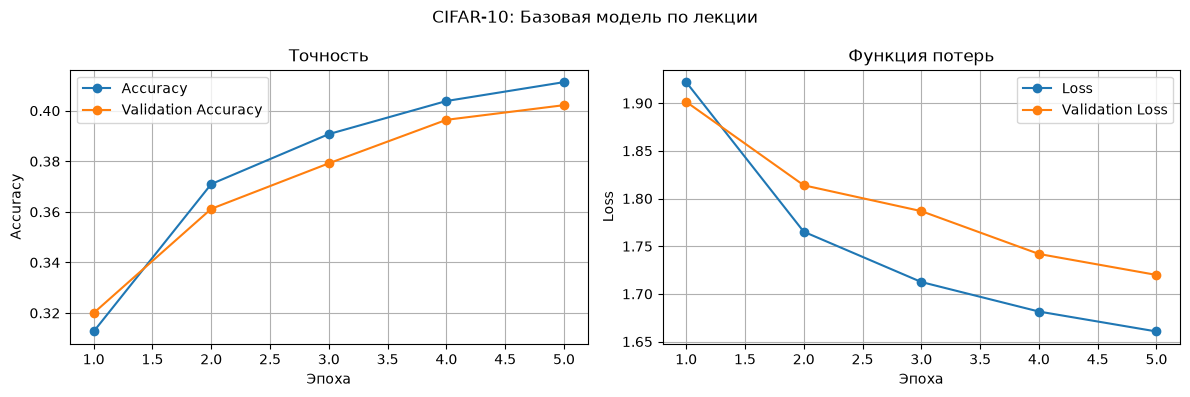

In [ ]:
# Базовая архитектура по лекции:
# входной слой -> Dense(128, ReLU) -> Dense(10, Softmax)
# Adam, Sparse Categorical Crossentropy, validation_split=0.1,
# 5 эпох, batch_size=32.

history_mnist = run_experiment(
    dataset_name="MNIST",
    experiment_name="Базовая модель по лекции",
    hidden_units=(128,),
    activation="relu",
    epochs=5,
    batch_size=32
)

history_fashion = run_experiment(
    dataset_name="Fashion-MNIST",
    experiment_name="Базовая модель по лекции",
    hidden_units=(128,),
    activation="relu",
    epochs=5,
    batch_size=32
)

history_cifar = run_experiment(
    dataset_name="CIFAR-10",
    experiment_name="Базовая модель по лекции",
    hidden_units=(128,),
    activation="relu",
    epochs=5,
    batch_size=32
)


Fashion-MNIST — Tanh, 10 эпох
Скрытые слои: (128,)
Функция активации: tanh
Эпохи: 10 | Batch size: 32


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ hidden_layer_1 (Dense)               │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ output_layer (Dense)                 │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
1688/1688 - 2s - 1ms/step - accuracy: 0.8257 - loss: 0.4867 - val_accuracy: 0.8555 - val_loss: 0.3977
Epoch 2/10
1688/1688 - 2s - 1ms/step - accuracy: 0.8635 - loss: 0.3751 - val_accuracy: 0.8628 - val_loss: 0.3699
Epoch 3/10
1688/1688 - 2s - 1ms/step - accuracy: 0.8763 - loss: 0.3379 - val_accuracy: 0.8702 - val_loss: 0.3477
Epoch 4/10
1688/1688 - 2s - 1ms/step - accuracy: 0.8851 - loss: 0.3126 - val_accuracy: 0.8735 - val_loss: 0.3361
Epoch 5/10
1688/1688 - 2s - 1ms/step - accuracy: 0.8918 - loss: 0.2936 - val_accuracy: 0.8760 - val_loss: 0.3319
Epoch 6/10
1688/1688 - 2s - 1ms/step - accuracy: 0.8976 - loss: 0.2779 - val_accuracy: 0.8802 - val_loss: 0.3278
Epoch 7/10
1688/1688 - 2s - 1ms/step - accuracy: 0.9023 - loss: 0.2651 - val_accuracy: 0.8803 - val_loss: 0.3272
Epoch 8/10
1688/1688 - 2s - 1ms/step - accuracy: 0.9063 - loss: 0.2532 - val_accuracy: 0.8810 - val_loss: 0.3291
Epoch 9/10
1688/1688 - 2s - 1ms/step - accuracy: 0.9109 - loss: 0.2425 - val_accuracy: 0.8783 - 

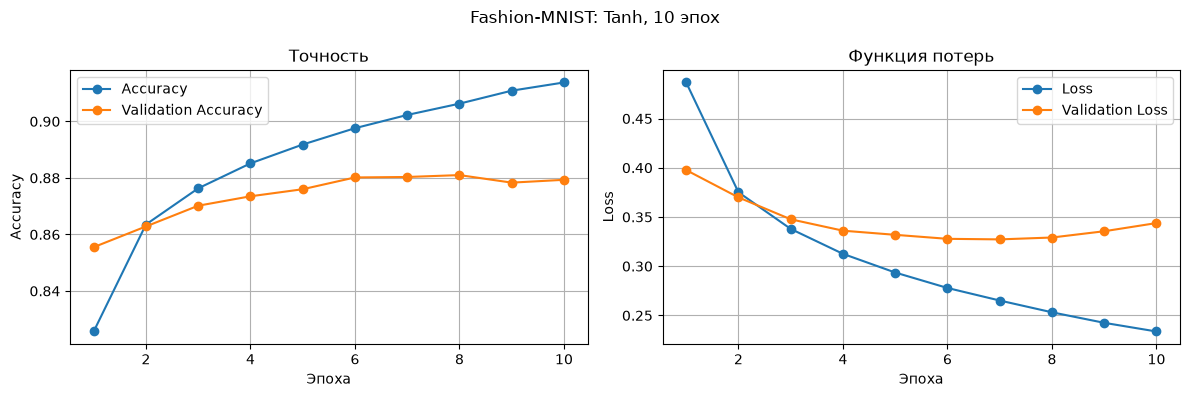


CIFAR-10 — Два скрытых слоя: 256 и 128 нейронов
Скрытые слои: (256, 128)
Функция активации: relu
Эпохи: 5 | Batch size: 32


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 3072)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ hidden_layer_1 (Dense)               │ (None, 256)                 │         786,688 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ hidden_layer_2 (Dense)               │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ output_layer (Dense)                 │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 820,874 (3.13 MB)

 Trainable params: 820,874 (3.13 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
1407/1407 - 3s - 2ms/step - accuracy: 0.3284 - loss: 1.8704 - val_accuracy: 0.3834 - val_loss: 1.7346
Epoch 2/5
1407/1407 - 3s - 2ms/step - accuracy: 0.3938 - loss: 1.6977 - val_accuracy: 0.4240 - val_loss: 1.6278
Epoch 3/5
1407/1407 - 3s - 2ms/step - accuracy: 0.4243 - loss: 1.6123 - val_accuracy: 0.4284 - val_loss: 1.6115
Epoch 4/5
1407/1407 - 3s - 2ms/step - accuracy: 0.4449 - loss: 1.5567 - val_accuracy: 0.4404 - val_loss: 1.5950
Epoch 5/5
1407/1407 - 3s - 2ms/step - accuracy: 0.4573 - loss: 1.5211 - val_accuracy: 0.4568 - val_loss: 1.5805

Время обучения: 14.17 сек.
Accuracy на обучении:   45.73%
Accuracy на validation: 45.68%
Accuracy на тесте:      44.50%
Loss на тесте:          1.5688


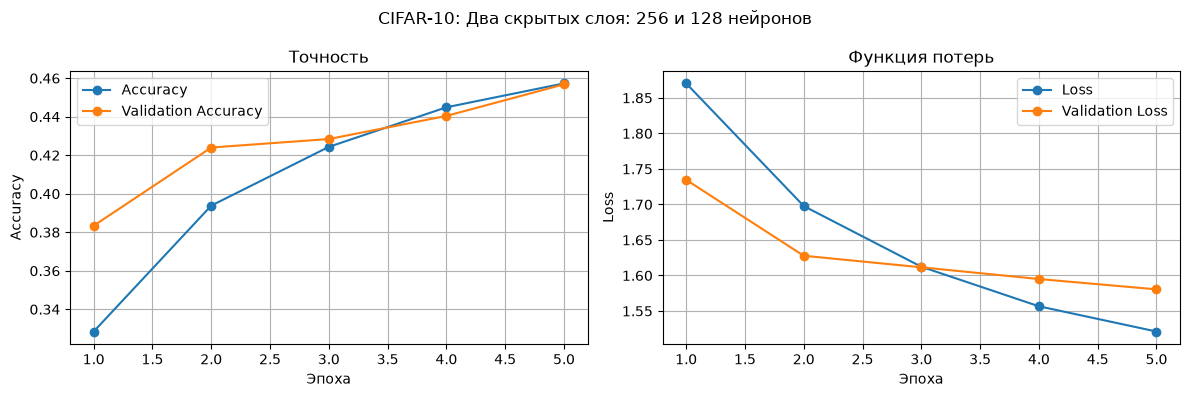

In [ ]:
# Численный эксперимент 1:
# Изменяем функцию активации и число эпох для Fashion-MNIST.

history_fashion_variant = run_experiment(
    dataset_name="Fashion-MNIST",
    experiment_name="Tanh, 10 эпох",
    hidden_units=(128,),
    activation="tanh",
    epochs=10,
    batch_size=32
)

# Численный эксперимент 2:
# Добавляем скрытый слой и увеличиваем число нейронов для CIFAR-10.

history_cifar_variant = run_experiment(
    dataset_name="CIFAR-10",
    experiment_name="Два скрытых слоя: 256 и 128 нейронов",
    hidden_units=(256, 128),
    activation="relu",
    epochs=5,
    batch_size=32
)

In [ ]:
results_df = pd.DataFrame(results)

display(
    results_df.style.format({
        "Accuracy (train)": "{:.4f}",
        "Accuracy (validation)": "{:.4f}",
        "Accuracy (test)": "{:.4f}",
        "Loss (test)": "{:.4f}",
        "Время обучения, сек.": "{:.2f}"
    })
)

,Датасет,Эксперимент,Скрытые слои,Активация,Эпохи,Batch size,Accuracy (train),Accuracy (validation),Accuracy (test),Loss (test),"Время обучения, сек."
0,MNIST,Базовая модель по лекции,"(128,)",relu,5,32,0.9874,0.9752,0.9732,0.0898,9.55
1,Fashion-MNIST,Базовая модель по лекции,"(128,)",relu,5,32,0.8934,0.8805,0.8723,0.3577,9.22
2,CIFAR-10,Базовая модель по лекции,"(128,)",relu,5,32,0.4113,0.4022,0.3958,1.7087,10.07
3,Fashion-MNIST,"Tanh, 10 эпох","(128,)",tanh,10,32,0.9138,0.8793,0.8740,0.3652,18.01
4,CIFAR-10,Два скрытых слоя: 256 и 128 нейронов,"(256, 128)",relu,5,32,0.4573,0.4568,0.4450,1.5688,14.17
